# 01 · Data, data quality and exploratory analysis
**Matching spirits supply to demand in Iowa** — decision support for the Iowa Alcoholic Beverages Division (ABD)
Group 1 · Darshita Yadav (240981) · Raghav Yadav (240598) · Rayna Manchanda (240601) · Prerit Shrivastava (240593)

> **At a glance**
> * 4.52 million order lines (Jan 2025 – Oct 2026) from five official sources, joined into one table.
> * Seven data defects found and fixed. The biggest: the publisher truncated liters, dollars and prices in three months.
> * EDA shows five patterns that shape the rest of the project: a shrinking market (−3%), one-weekday ordering,
>   a collapse in purchases near Missouri, agave following the Hispanic population, and frequent store openings.

**How to read this notebook.** Each section starts with *what* we do and *why*, then a short code cell, then
what the result means. Every EDA technique has a small card explaining what it is and how to read it.
Findings use the format **Observation → Inference → Decision relevance**.

**Contents**
1. The business problem
2. Data sources
3. Building one table (the SSOT)
4. Data quality: what was wrong and how it was fixed
5. Exploratory data analysis (12 techniques)
6. What EDA hands to the next notebooks

## Setup
Libraries, project paths and one plotting style for every chart. The project code lives in `src/abd_demand/`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))       # make the project package importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from abd_demand import config as C, plotting as P       # paths/constants and the chart style

import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # hide font warnings
P.use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

dq = json.loads(C.DQ_REPORT.read_text())                 # data-quality log written by the ETL script

## 1. The business problem

| | |
|---|---|
| **Stakeholder** | Iowa ABD: the state's only wholesaler of spirits. It buys from suppliers, stores stock in one central warehouse and delivers to ~2,240 licensed stores. ABD also issues those licences. |
| **Problem** | ABD must buy and truck stock *before* stores order. Today's rule ("plan the same month as last year") over-buys in a shrinking market and ignores *where* and *why* demand differs. |
| **Decision** | How many liters of each spirits family to plan for each county next month; how to treat border counties and newly licensed stores. |
| **KPI** | Planning error (WAPE, county × family) at least 10% lower than the status quo, with bias within ±3%. |
| **Constraints** | Public data only; one state price (ABD cannot price by region); ABD is also the regulator, so the goal is *accurate* supply, not *more* sales. |

## 2. Data sources
Five sources from four publishers, all official and none from Kaggle. Links and licences are also in `data/links.txt`.

In [2]:
sources = pd.DataFrame([
    ["Iowa Liquor Sales 2025", "Iowa Data Hub (dataset 1262)", "Jan–Dec 2025", f"{dq['rows_read_dataset_1262']:,} rows", "every order a store placed with ABD"],
    ["Iowa Liquor Sales 2026", "Iowa Data Hub (dataset 1263)", "Jan–Oct 2026", f"{dq['rows_read_dataset_1263']:,} rows", "same, new year: the confirmation sample"],
    ["ACS 5-year 2020–24",     "US Census Bureau (16 tables)", "2020–24 avg", "99 counties", "population, income, age, education, ethnicity"],
    ["County adjacency + Gazetteer", "US Census Bureau", "2024", "99 counties", "which counties touch which state; area; location"],
    ["Spirits excise tax",     "Tax Foundation", "Jan 2026", "7 states", "tax gap between Iowa and each neighbour"],
], columns=["source", "publisher", "period", "size", "what it tells us"])
sources

,source,publisher,period,size,what it tells us
0,Iowa Liquor Sales 2025,Iowa Data Hub (dataset 1262),Jan–Dec 2025,"2,490,620 rows",every order a store placed with ABD
1,Iowa Liquor Sales 2026,Iowa Data Hub (dataset 1263),Jan–Oct 2026,"2,029,764 rows","same, new year: the confirmation sample"
2,ACS 5-year 2020–24,US Census Bureau (16 tables),2020–24 avg,99 counties,"population, income, age, education, ethnicity"
3,County adjacency + Gazetteer,US Census Bureau,2024,99 counties,which counties touch which state; area; location
4,Spirits excise tax,Tax Foundation,Jan 2026,7 states,tax gap between Iowa and each neighbour


## 3. Building one table: the single source of truth (SSOT)
`scripts/01_build_ssot.py` rebuilds everything from the raw files in about a minute:

```
 raw sales 2025 + 2026 ──► check row counts ──► clean ──► derive new columns ──► join census + geography + tax ──► SSOT (parquet)
                             vs publisher        (sec. 4)   liters, dollars,       on 5-digit county FIPS code        4.52M rows × 76 columns
                                                            family, store type
```

**Why join on the FIPS code and not the county name?** Names are spelt differently across sources
("O'Brien" vs "OBrien"). FIPS is a federal standard code, so the join cannot silently miss a county.

The checks below must all pass, or the pipeline stops.

In [3]:
checks = pd.DataFrame({
    "check": ["2025 rows read = rows the publisher lists",
              "2026 rows read = rows the publisher lists",
              "share of sales rows matched to a census county",
              "counties in the census profile"],
    "observed": [dq["rows_read_dataset_1262"], dq["rows_read_dataset_1263"],
                 dq["census_join_match_rate"], dq["county_profile"]["counties"]],
    "expected": [dq["rows_published_dataset_1262"], dq["rows_published_dataset_1263"], 1.0, 99],
})
checks["passed"] = checks.observed == checks.expected
checks[["observed", "expected"]] = checks[["observed", "expected"]].map("{:,.0f}".format)   # print counts without decimals
print(f"SSOT: {dq['ssot']['rows']:,} rows x {dq['ssot']['columns']} columns")
checks

SSOT: 4,518,330 rows x 76 columns


,check,observed,expected,passed
0,2025 rows read = rows the publisher lists,"2,490,620","2,490,620",True
1,2026 rows read = rows the publisher lists,"2,029,764","2,029,764",True
2,share of sales rows matched to a census county,1,1,True
3,counties in the census profile,99,99,True


## 4. Data quality: what was wrong and how each issue was treated
Several of these were **not known at the pre-submission stage**; the 2026 file and a closer audit surfaced them.

In [4]:
mm = dq["mini_multipack_suspect"]
issues = pd.DataFrame([
    ["Duplicated download file (2025 part 5)", "429,989 rows", "file excluded; parts 1–4 match the publisher's count exactly"],
    ["Exact duplicate rows", f"{sum(dq['exact_duplicates_removed'].values())} rows", "removed"],
    ["Blank county", f"{dq['blank_county_rows']:,} rows", f"{dq['blank_county_imputed_from_store']:,} filled from the store's county; {dq['rows_dropped_no_county']:,} dropped (0.05%)"],
    ["Liters truncated to whole numbers (Nov–Dec 2025, Jan 2026)", f"−{dq['liters_understated_by_source_in_truncated_months_pct']}% in those months", "liters recomputed = bottles × bottle size, for every row"],
    ["Dollars and prices truncated in the same months", f"−{dq['dollars_source_understated_in_truncated_months_pct']}%", "dollars rebuilt from each item's price in the nearest clean month (validated: 0.08% error)"],
    ["Wholesale cost blank Jan–Jun 2025", "1.2M rows", "price per liter taken from dollars ÷ liters instead"],
    ["Multi-pack minis (one 'bottle' = a sleeve of 50 ml minis)", f"{mm['items']} items", "flagged; excluded from price metrics; ~2% of liters understated"],
    ["Returns (negative bottles)", f"{dq['return_rows_kept_as_negative_volume']:,} rows", "kept as negative volume; excluded from prices"],
    ["New licence at an existing address (owner change)", f"{dq['store_entry_types']['ownership_change']} stores", "classified separately from genuinely new stores (critical for H3)"],
], columns=["issue", "size", "treatment"])
issues

,issue,size,treatment
0,Duplicated download file (2025 part 5),"429,989 rows",file excluded; parts 1–4 match the publisher's...
1,Exact duplicate rows,21 rows,removed
2,Blank county,"4,135 rows","2,102 filled from the store's county; 2,033 dr..."
3,Liters truncated to whole numbers (Nov–Dec 202...,−3.43% in those months,"liters recomputed = bottles × bottle size, for..."
4,Dollars and prices truncated in the same months,−0.4%,dollars rebuilt from each item's price in the ...
5,Wholesale cost blank Jan–Jun 2025,1.2M rows,price per liter taken from dollars ÷ liters in...
6,Multi-pack minis (one 'bottle' = a sleeve of 5...,313 items,flagged; excluded from price metrics; ~2% of l...
7,Returns (negative bottles),"4,019 rows",kept as negative volume; excluded from prices
8,New licence at an existing address (owner change),55 stores,classified separately from genuinely new store...


**Seeing the truncation.** In a normal month about a third of order lines have whole-number liters
(e.g. 12 × 1 L). If a month shows 100%, the publisher rounded the values down.

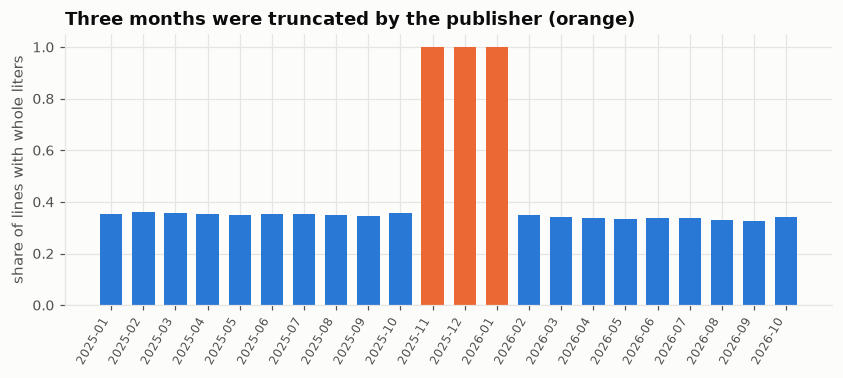

In [5]:
published = pd.read_parquet(C.SSOT, columns=["month", "sales_liters_published"])
published["month"] = published.month.astype(str)
published["whole_number"] = published.sales_liters_published == published.sales_liters_published.round()
share_whole = published.groupby("month").whole_number.mean()

colors = [P.ORANGE if v > 0.9 else P.BLUE for v in share_whole]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(share_whole.index, share_whole.values, color=colors, width=0.7)
ax.set_ylabel("share of lines with whole liters")
ax.set_title("Three months were truncated by the publisher (orange)")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8)
P.save(fig, "dq_truncation"); plt.show()
del published

**Observation.** Nov 2025, Dec 2025 and Jan 2026 are at 100%; every other month is at ~30–35%.
**Inference.** A 50 ml mini reads as 0 L in those months, so the published liters understate them by 3.4%:
a false holiday slump.
**Decision relevance.** All volumes in this project use recomputed liters, and the defect is reported back to the publisher.

## 5. Exploratory data analysis
We load the columns we need once. Each row is **one order line**: one product ordered by one store on one day.

In [6]:
cols = ["ordered_on", "month", "year", "store_no", "county_fips_code", "family", "store_type",
        "bottle_volume_ml", "bottle_size_class", "sales_bottles", "liters", "dollars", "price_per_liter"]
df = pd.read_parquet(C.SSOT, columns=cols)
for c in ["month", "store_no", "county_fips_code", "family", "store_type", "bottle_size_class"]:
    df[c] = df[c].astype(str)

county = pd.read_parquet(C.PROCESSED / "county_period.parquet")   # one row per county per period
stores = pd.read_parquet(C.STORE_DIM)                              # one row per store
print(f"{len(df):,} order lines | {df.store_no.nunique():,} stores | {df.county_fips_code.nunique()} counties")

4,518,330 order lines | 2,401 stores | 99 counties


### 5.1 Data profiling
> **Technique card — data profiling.** *What:* a first look at size, column types and missing values.
> *Why:* before any chart we need to know what each column is and how complete it is.
> *How to read:* a missing share above a few percent needs an explanation before the column is used.

In [7]:
profile = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing %": (100 * df.isna().mean()).round(2),
    "distinct values": df.nunique(),
})
profile

,type,missing %,distinct values
ordered_on,datetime64[ms],0.00,555
month,str,0.00,22
year,int16,0.00,2
store_no,str,0.00,2401
county_fips_code,str,0.00,99
family,str,0.00,9
store_type,str,0.00,7
bottle_volume_ml,int64,0.00,26
bottle_size_class,str,0.00,4
sales_bottles,int64,0.00,400


**Observation.** Only `price_per_liter` has gaps (7.5% of lines: returns and multi-pack minis have no valid price, by design).
Every other column is complete. **Decision relevance.** Price metrics simply skip those rows.

### 5.2 Summary statistics
> **Technique card — descriptive statistics.** *What:* count, mean, spread (std) and percentiles of each numeric column.
> *Why:* shows the typical value and how skewed the data is.
> *How to read:* if the **mean is far above the median (50%)**, a few very large values pull it up (right skew).

In [8]:
numeric = df[["sales_bottles", "liters", "dollars", "price_per_liter", "bottle_volume_ml"]]
numeric.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,25%,50%,75%,99%,max
sales_bottles,"4,518,330.00",12.22,34.95,-528.00,2.00,6.00,12.00,96.00,"13,200.00"
liters,"4,518,330.00",8.83,40.55,-189.00,1.20,4.50,9.00,72.00,"13,200.00"
dollars,"4,518,330.00",169.41,617.43,"-3,240.00",51.00,90.00,170.88,"1,377.00","260,832.00"
price_per_liter,"4,179,874.00",36.95,62.65,2.83,12.65,20.25,34.99,210.00,"7,784.29"
bottle_volume_ml,"4,518,330.00",761.39,537.95,20.00,375.00,750.00,"1,000.00","1,750.00","5,250.00"


**Observation.** A typical order line is small (median 4.5 L, i.e. six bottles), but the mean is almost twice that
(8.8 L) and the largest line is 13,200 L: the data is strongly **right-skewed**. The negative minimums are returns.
**Inference.** Averages are dominated by a few huge orders (warehouse clubs). Medians and log scales describe the
typical store better. **Decision relevance.** This skew is why the forecast uses a Tweedie loss (notebook 03).

### 5.3 Distributions: histograms on a log scale
> **Technique card — histogram.** *What:* bars counting how many values fall in each range.
> *Why:* shows the *shape* of a variable: symmetric, skewed, or with several peaks.
> *Log scale:* when values span several orders of magnitude (1 L to 5,000 L), a log axis spreads them out so the
> shape is visible.

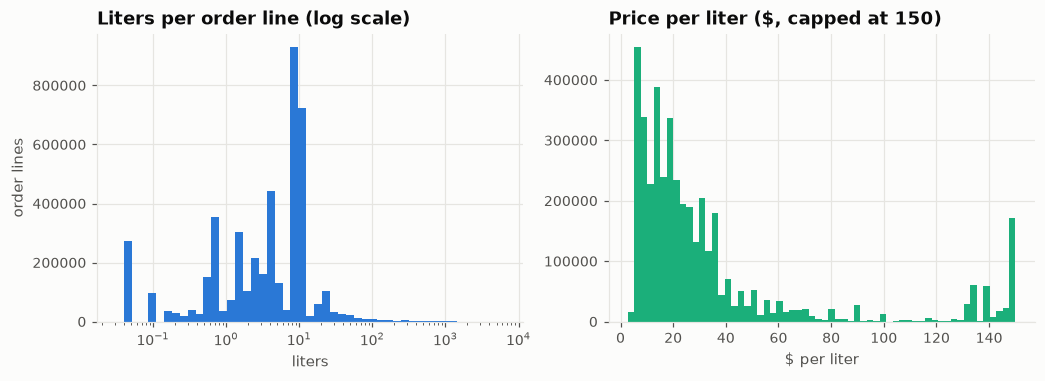

median price $20.25/L; 75th percentile $34.99/L


In [9]:
positive = df[df.liters > 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

bins = np.logspace(-1.5, 3.8, 50)
axes[0].hist(positive.liters, bins=bins, color=P.BLUE)
axes[0].set_xscale("log")
axes[0].set_title("Liters per order line (log scale)")
axes[0].set_xlabel("liters"); axes[0].set_ylabel("order lines")

price = df.price_per_liter.dropna()
axes[1].hist(price.clip(upper=150), bins=60, color=P.AQUA)
axes[1].set_title("Price per liter ($, capped at 150)")
axes[1].set_xlabel("$ per liter")
plt.show()
print(f"median price ${price.median():.2f}/L; 75th percentile ${price.quantile(0.75):.2f}/L")

**Observation.** Liters per line peak at a few liters and taper over three orders of magnitude. The middle half of
lines cost $13–35 per liter (median $20), with a long tail of premium bottles.
**Inference.** Two very different kinds of order coexist: small convenience-store top-ups and large bulk orders.
**Decision relevance.** A single average would mislead; we plan by store type and size band.

### 5.4 Outliers: box plots and the IQR rule
> **Technique card — box plot.** The box spans the middle 50% of values (25th to 75th percentile, the
> *interquartile range*, IQR); the line inside is the median. Points beyond 1.5 × IQR from the box are flagged as outliers.
> *Why:* a quick, distribution-free way to spot unusual values and compare groups.
> *Key question:* is an outlier an **error** (fix or drop) or a **real but rare** value (keep)?

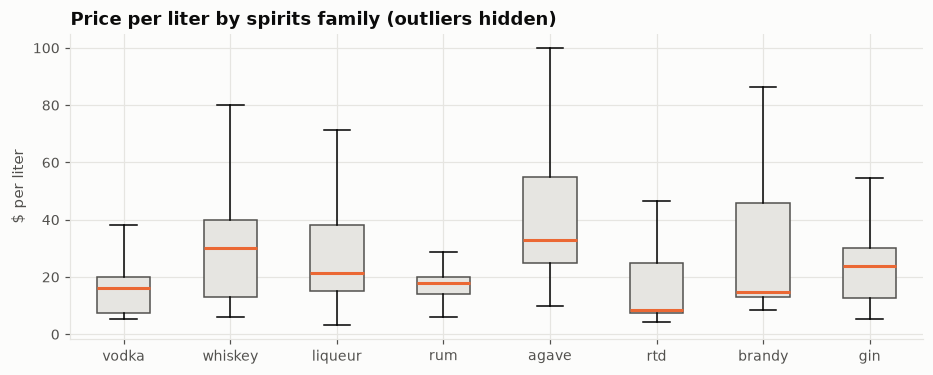

IQR rule: values above $68/L are outliers -> 12.2% of priced lines


In [10]:
families = ["vodka", "whiskey", "liqueur", "rum", "agave", "rtd", "brandy", "gin"]
priced = df[df.price_per_liter.notna() & df.family.isin(families)]
groups = [priced.loc[priced.family == f, "price_per_liter"] for f in families]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot(groups, tick_labels=families, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=P.GRID, color=P.INK2), medianprops=dict(color=P.ORANGE, lw=2))
ax.set_ylabel("$ per liter"); ax.set_title("Price per liter by spirits family (outliers hidden)")
plt.show()

q1, q3 = price.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR rule: values above ${upper:.0f}/L are outliers -> {100 * (price > upper).mean():.1f}% of priced lines")

**Observation.** Ready-to-drink cocktails (RTD), vodka and rum are the cheapest per liter; agave has the highest
median (~$33/L), and whiskey, agave and brandy have the widest spread. About one priced line in eight is an
"outlier" by the IQR rule, because the distribution has a long right tail.
**Inference.** These are real collectors' and premium bottles, not errors. (The real errors, multi-pack minis
priced at $1,600/L, were removed in section 4.)
**Decision relevance.** Outliers are **kept**: dropping them would under-plan the premium shelf.

### 5.5 Categorical frequencies: bar charts
> **Technique card — frequency bar chart.** *What:* the total (or share) for each category, sorted.
> *Why:* shows which categories matter; a sorted bar chart is easier to read than a pie chart.
> *How to read:* compare bar lengths; the first few bars usually carry most of the volume.

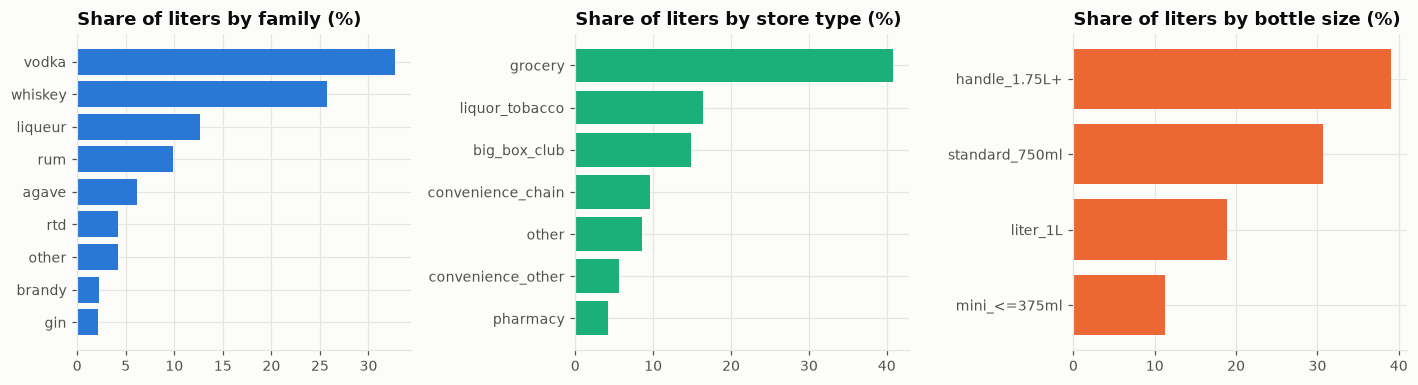

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

by_family = df.groupby("family").liters.sum().sort_values()
axes[0].barh(by_family.index, 100 * by_family / by_family.sum(), color=P.BLUE)
axes[0].set_title("Share of liters by family (%)")

by_type = stores.groupby("store_type").liters_total.sum().sort_values()
axes[1].barh(by_type.index, 100 * by_type / by_type.sum(), color=P.AQUA)
axes[1].set_title("Share of liters by store type (%)")

by_size = df.groupby("bottle_size_class").liters.sum().sort_values()
axes[2].barh(by_size.index, 100 * by_size / by_size.sum(), color=P.ORANGE)
axes[2].set_title("Share of liters by bottle size (%)")
plt.tight_layout(); plt.show()

**Observation.** Vodka and whiskey are almost 60% of all liters. Grocery stores carry ~40% of volume, followed by
liquor stores and warehouse clubs (~15% each). The 1.75 L "handle" and the 750 ml bottle carry ~70% of liters, even
though minis are the most numerous bottles.
**Decision relevance.** The forecast is built per spirits family and uses store type as a feature.

### 5.6 Time series: trend and year-over-year change
> **Technique card — line chart and year-over-year (YoY) comparison.** *What:* a value plotted over time; YoY
> compares each month with the same month a year earlier.
> *Why:* YoY removes seasonality (December is always big), so what remains is the real trend.

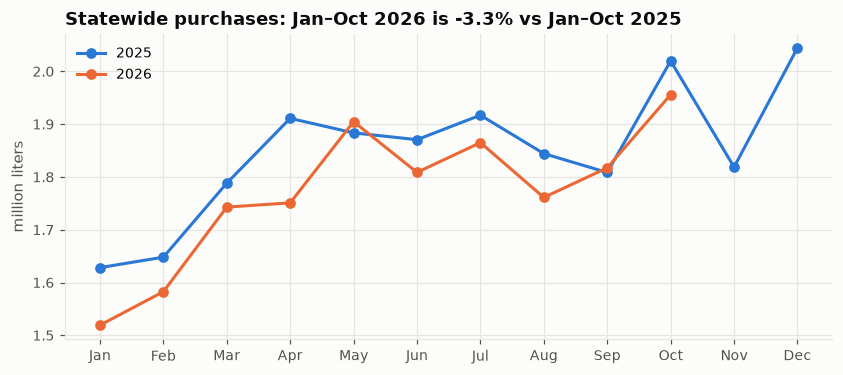

YoY change by month (%):
Jan   -6.70
Feb   -4.00
Mar   -2.50
Apr   -8.40
May    1.10
Jun   -3.30
Jul   -2.70
Aug   -4.50
Sep    0.50
Oct   -3.20


In [12]:
monthly = df.groupby("month").liters.sum() / 1e6                 # million liters per month
y2025 = monthly[monthly.index.str.startswith("2025")].values
y2026 = monthly[monthly.index.str.startswith("2026")].values
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(month_names, y2025, marker="o", label="2025", color=P.BLUE)
ax.plot(month_names[:len(y2026)], y2026, marker="o", label="2026", color=P.ORANGE)
ax.set_ylabel("million liters"); ax.legend()
ytd_change = y2026.sum() / y2025[:len(y2026)].sum() - 1
ax.set_title(f"Statewide purchases: Jan–Oct 2026 is {100 * ytd_change:.1f}% vs Jan–Oct 2025")
P.save(fig, "eda_monthly_yoy"); plt.show()

yoy = pd.Series(100 * (y2026 / y2025[:len(y2026)] - 1), index=month_names[:len(y2026)]).round(1)
print("YoY change by month (%):"); print(yoy.to_string())

**Observation.** 2026 is about 3% below 2025, and lower in 8 of the 10 months.
**Inference.** The market is shrinking slightly, in line with falling US alcohol consumption.
**Decision relevance.** "Same month last year" — the status quo — therefore **over-buys** every month. This is the
baseline the forecast must beat.

### 5.7 Seasonality index
> **Technique card — seasonal index.** *What:* each month's volume divided by the average month (1.0 = average).
> *Why:* tells a planner how much above or below normal to plan each month.

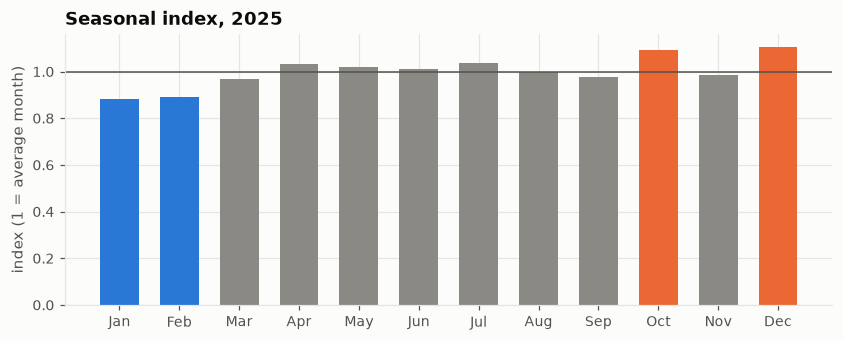

In [13]:
season = pd.Series(y2025 / y2025.mean(), index=month_names)
colors = [P.ORANGE if v > 1.05 else P.BLUE if v < 0.95 else P.MUTED for v in season]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(season.index, season.values, color=colors, width=0.65)
ax.axhline(1, color=P.INK2, lw=1)
ax.set_ylabel("index (1 = average month)"); ax.set_title("Seasonal index, 2025")
plt.show()

**Observation.** October and December are the peaks (~10% above average: stores stock up for the holidays);
April–July sit slightly above average; January and February are ~11% below.
**Decision relevance.** A plan must follow the season; a flat monthly average would stock out in peaks and overstock in troughs.

### 5.8 Weekday pattern: how stores order
> **Technique card — grouped totals + concentration share.** We sum liters by weekday, then for each store compute
> the share of its liters on its single busiest weekday. A share near 100% means the store orders on one fixed day.

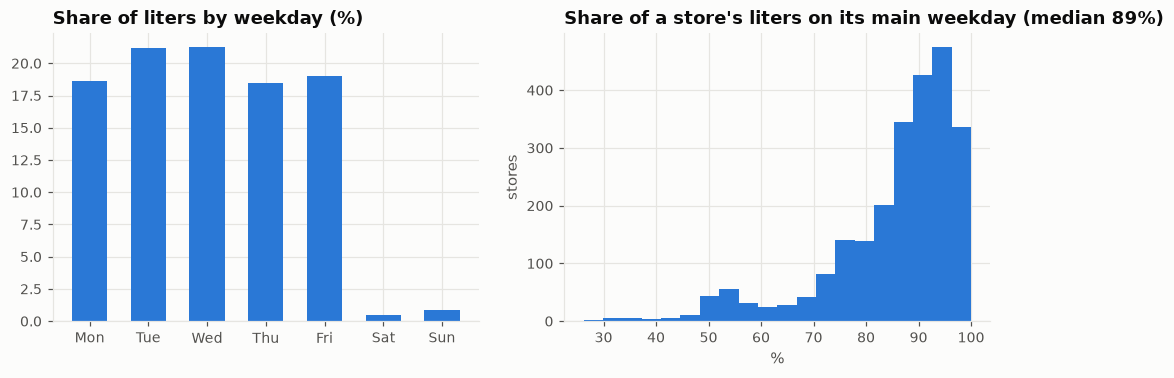

In [14]:
orders = df[df.liters > 0][["ordered_on", "store_no", "liters"]].copy()
orders["weekday"] = orders.ordered_on.dt.day_name().str[:3]
weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = orders.groupby("weekday").liters.sum().reindex(weekday_order)

store_weekday = orders.groupby(["store_no", "weekday"]).liters.sum().unstack(fill_value=0)
main_day_share = store_weekday.max(axis=1) / store_weekday.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(by_weekday.index, 100 * by_weekday / by_weekday.sum(), color=P.BLUE, width=0.6)
axes[0].set_title("Share of liters by weekday (%)")
axes[1].hist(100 * main_day_share, bins=20, color=P.BLUE)
axes[1].set_title(f"Share of a store's liters on its main weekday (median {100 * main_day_share.median():.0f}%)")
axes[1].set_xlabel("%"); axes[1].set_ylabel("stores")
P.save(fig, "eda_weekday"); plt.show()
del orders

**Observation.** Deliveries happen Monday–Friday, and the median store puts ~89% of its liters on **one** weekday.
**Inference.** A month with five of a store's order days carries ~25% more volume than a month with four. Much of the
"noise" in monthly demand is just the calendar.
**Decision relevance.** This becomes a forecasting feature (order days per month), and ABD should plan truck
capacity by delivery days, not by months.

### 5.9 Relationship between two numeric variables: scatter plot
> **Technique card — scatter plot.** *What:* one dot per unit (here, a county), x = one variable, y = another.
> *Why:* shows whether two variables move together, the shape of the relationship, and unusual points.
> *How to read:* a slope means association, **not** causation; other factors may drive both.

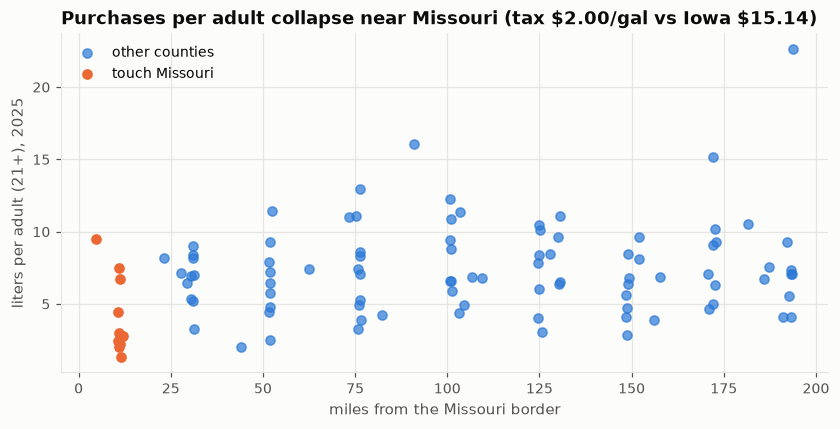

In [15]:
fy = county[county.period == "FY2025"]
border = fy[fy.geo_borders_mo == 1]
others = fy[fy.geo_borders_mo == 0]

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(others.geo_miles_to_mo_border, others.liters_per_adult, color=P.BLUE, alpha=0.7, label="other counties")
ax.scatter(border.geo_miles_to_mo_border, border.liters_per_adult, color=P.ORANGE, label="touch Missouri")
ax.set_xlabel("miles from the Missouri border"); ax.set_ylabel("liters per adult (21+), 2025")
ax.set_title(r"Purchases per adult collapse near Missouri (tax \$2.00/gal vs Iowa \$15.14)")
ax.legend()
P.save(fig, "eda_mo_border"); plt.show()

### 5.10 Comparing groups: box plot by group
> **Technique card — grouped box plot.** Same box plot as 5.4, one box per group, to compare whole distributions
> (not only averages) between groups.

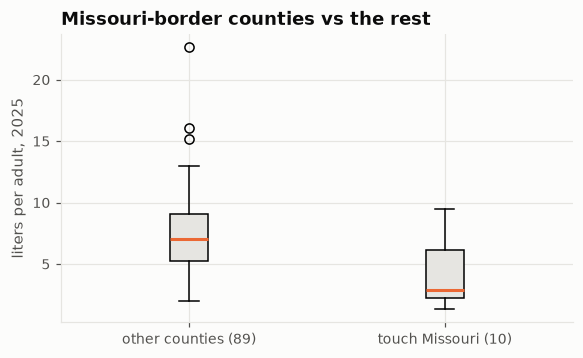

median: border 2.9 L vs others 7.0 L per adult


In [16]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.boxplot([others.liters_per_adult, border.liters_per_adult],
           tick_labels=["other counties (89)", "touch Missouri (10)"], patch_artist=True,
           boxprops=dict(facecolor=P.GRID), medianprops=dict(color=P.ORANGE, lw=2))
ax.set_ylabel("liters per adult, 2025"); ax.set_title("Missouri-border counties vs the rest")
plt.show()
print(f"median: border {border.liters_per_adult.median():.1f} L vs others {others.liters_per_adult.median():.1f} L per adult")

**Observation.** The ten counties touching Missouri buy about **half** as many liters per adult; their whole
distribution sits lower, not just one or two counties.
**Inference.** This fits cross-border shopping: Missouri taxes spirits at $2.00/gal vs Iowa's $15.14.
**Decision relevance.** Per-adult planning norms would over-supply border counties. This becomes **H1**, tested on
the unseen 2026 data in notebook 02.

### 5.11 Correlation analysis: heatmap
> **Technique card — correlation matrix.** *What:* a number from −1 to +1 for every pair of variables
> (+1 = move together perfectly, 0 = no linear link, −1 = move opposite). We use **Spearman** correlation, which works
> on ranks, so it is robust to skew and outliers (Pearson would be pulled by a few big counties).
> *Why:* a fast screen for which demographics relate to which outcomes, and which predictors overlap
> (*multicollinearity*: e.g. income and education move together, so a regression must not over-read either).
> *Caution:* correlation is not causation, and it only captures monotonic relationships.

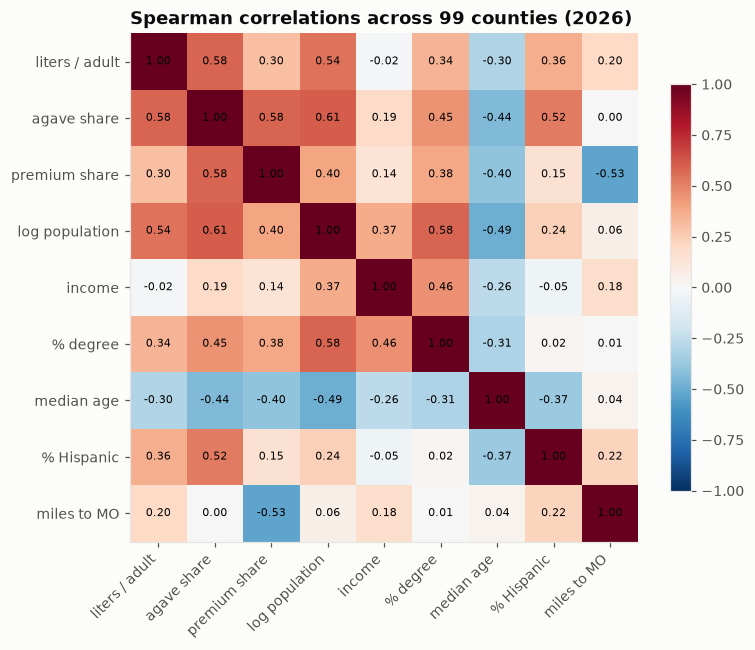

In [17]:
fy26 = county[county.period == "JanOct2026"]
heat_cols = {
    "liters_per_adult": "liters / adult", "agave_share": "agave share", "premium_share": "premium share",
    "log_population": "log population", "income_k": "income", "cty_pct_bachelors_or_higher": "% degree",
    "cty_median_age": "median age", "cty_pct_hispanic": "% Hispanic", "geo_miles_to_mo_border": "miles to MO",
}
corr = fy26[list(heat_cols)].rename(columns=heat_cols).corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlations across 99 counties (2026)")
plt.show()

**Observation.** Liters per adult rise with population (0.54); agave share rises with % Hispanic (0.52) but *also*
with population (0.61); population, education and income are correlated with each other. Distance from Missouri
shows only 0.20, even though the border effect in 5.9 is large: the effect is concentrated in the ten border counties,
and a correlation across all 99 dilutes a threshold effect like that.
**Inference.** Two lessons: overlapping predictors can take credit for each other, and a correlation can miss a
strong but local effect.
**Decision relevance.** The hypothesis tests (notebook 02) therefore use **regression with controls** for population,
income, age and education, not raw correlations.

### 5.12 Composition: agave share vs Hispanic population

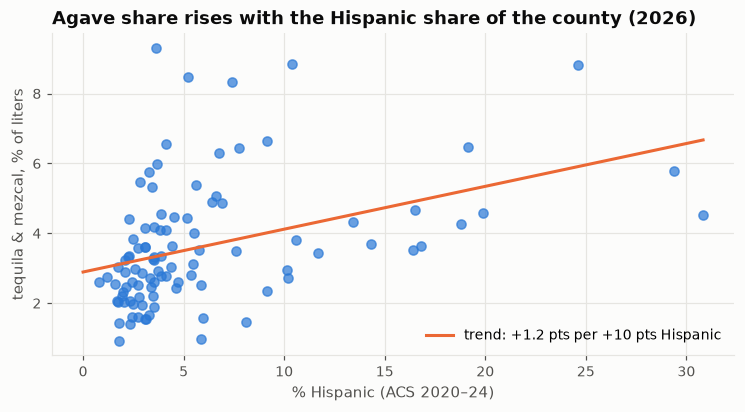

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(fy26.cty_pct_hispanic, 100 * fy26.agave_share, color=P.BLUE, alpha=0.7)
slope, intercept = np.polyfit(fy26.cty_pct_hispanic, 100 * fy26.agave_share, 1)
xs = np.linspace(0, fy26.cty_pct_hispanic.max(), 20)
ax.plot(xs, intercept + slope * xs, color=P.ORANGE, lw=2, label=f"trend: +{10 * slope:.1f} pts per +10 pts Hispanic")
ax.set_xlabel("% Hispanic (ACS 2020–24)"); ax.set_ylabel("tequila & mezcal, % of liters")
ax.set_title("Agave share rises with the Hispanic share of the county (2026)"); ax.legend()
P.save(fig, "eda_agave"); plt.show()

**Observation.** The agave share rises with % Hispanic, with exceptions (the two most Hispanic counties sit below
the line). **Decision relevance.** This informs the category *mix* per region (**H2**), not individual targeting.

### 5.13 Concentration: how many stores carry the volume? (Pareto curve)
> **Technique card — cumulative share (Pareto / Lorenz curve).** Sort stores from biggest to smallest and plot the
> running share of total liters. A curve that rises steeply means a few stores carry most of the volume (the "80/20 rule").

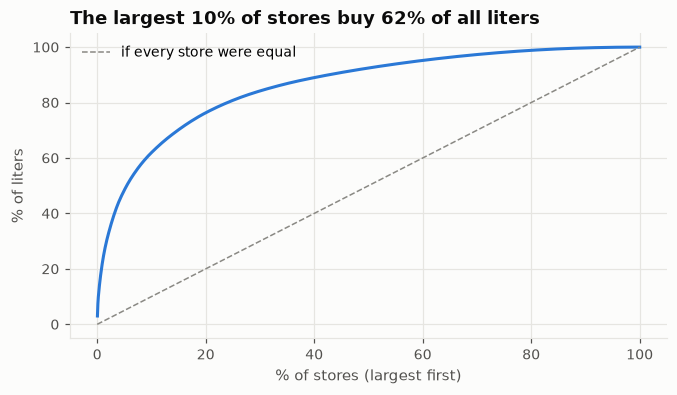

In [19]:
store_liters = stores.liters_total.sort_values(ascending=False).values
cumulative = np.cumsum(store_liters) / store_liters.sum()
pct_stores = np.arange(1, len(store_liters) + 1) / len(store_liters)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(100 * pct_stores, 100 * cumulative, color=P.BLUE)
ax.plot([0, 100], [0, 100], color=P.MUTED, ls="--", lw=1, label="if every store were equal")
top10 = cumulative[int(0.1 * len(cumulative)) - 1]
ax.set_xlabel("% of stores (largest first)"); ax.set_ylabel("% of liters")
ax.set_title(f"The largest 10% of stores buy {100 * top10:.0f}% of all liters"); ax.legend()
plt.show()

**Observation.** The largest 10% of stores (warehouse clubs, big supermarkets) buy 62% of all liters.
**Decision relevance.** Forecast errors on those few stores dominate total error, so the metric (WAPE) is
volume-weighted, and the largest series get special attention in notebook 03.

### 5.14 Store entry over time

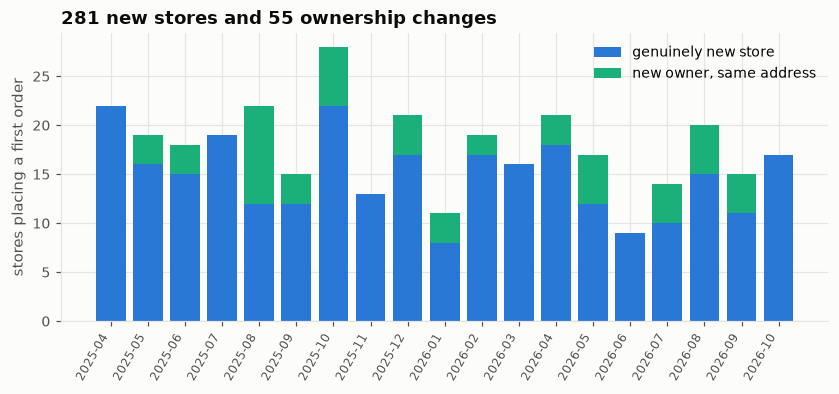

In [20]:
entrants = stores[stores.entry_type.isin(["new_store", "ownership_change"])]
by_month = entrants.groupby(["first_month", "entry_type"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(by_month.index, by_month["new_store"], color=P.BLUE, label="genuinely new store")
ax.bar(by_month.index, by_month["ownership_change"], bottom=by_month["new_store"], color=P.AQUA, label="new owner, same address")
ax.set_ylabel("stores placing a first order"); ax.legend()
ax.set_title(f"{(stores.entry_type == 'new_store').sum()} new stores and {(stores.entry_type == 'ownership_change').sum()} ownership changes")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8)
P.save(fig, "eda_entry"); plt.show()

**Observation.** About 15 genuinely new stores start ordering every month. Another 55 "new" licences are an
existing shop with a new owner.
**Inference.** Entry is frequent enough to study as a natural experiment, *if* ownership changes are separated out.
**Decision relevance.** ABD licenses these stores; whether a new store creates demand or moves it is **H3**.

## 6. What EDA hands to the next notebooks

| EDA technique | Finding | Becomes |
|---|---|---|
| Profiling, quality checks | three truncated months, multi-pack minis, ownership changes | cleaned SSOT; the H3 design |
| Summary stats, histograms | heavy right skew | Tweedie loss in the forecast (03) |
| Box plots, IQR | price outliers are real bottles | kept, not dropped |
| Time series, YoY | market −3% | the status quo over-buys; drift monitoring (04) |
| Seasonal index, weekday | strong seasons; one-weekday ordering | calendar features in the forecast (03) |
| Scatter, grouped box plot | Missouri-border collapse | **H1** (02) |
| Correlation heatmap | predictors overlap | regression with controls (02) |
| Composition scatter | agave vs % Hispanic | **H2** (02) |
| Pareto curve | few stores carry most volume | volume-weighted metric (WAPE) |
| Entry over time | ~15 new stores a month | **H3** (02) |

In [21]:
del df